<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/Latihan_BAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer

# 1. Memuat Dataset (Contoh menggunakan Breast Cancer dataset)
data = load_breast_cancer()
X = data.data
y = data.target

# 2. Split Data menjadi Train dan Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data berhasil disiapkan!")
print(f"Jumlah data train: {len(X_train)}")
print(f"Jumlah data test: {len(X_test)}")

Data berhasil disiapkan!
Jumlah data train: 455
Jumlah data test: 114


In [2]:
print("=== Praktikum 1: Eksperimen Parameter Pre-Pruning ===")
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        # Membuat model
        model = DecisionTreeClassifier(max_depth=depth,
                                       min_samples_leaf=min_leaf,
                                       random_state=42)
        # Training model
        model.fit(X_train, y_train)

        # Prediksi dan evaluasi
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        # Cetak hasil
        print(f"max_depth={str(depth):<4} | min_samples_leaf={min_leaf:<2} | akurasi test={acc:.3f}")

=== Praktikum 1: Eksperimen Parameter Pre-Pruning ===
max_depth=2    | min_samples_leaf=1  | akurasi test=0.930
max_depth=2    | min_samples_leaf=5  | akurasi test=0.930
max_depth=2    | min_samples_leaf=10 | akurasi test=0.930
max_depth=4    | min_samples_leaf=1  | akurasi test=0.947
max_depth=4    | min_samples_leaf=5  | akurasi test=0.947
max_depth=4    | min_samples_leaf=10 | akurasi test=0.947
max_depth=6    | min_samples_leaf=1  | akurasi test=0.939
max_depth=6    | min_samples_leaf=5  | akurasi test=0.956
max_depth=6    | min_samples_leaf=10 | akurasi test=0.947
max_depth=None | min_samples_leaf=1  | akurasi test=0.947
max_depth=None | min_samples_leaf=5  | akurasi test=0.956
max_depth=None | min_samples_leaf=10 | akurasi test=0.947


=== Praktikum 2: Cost Complexity Pruning Path ===


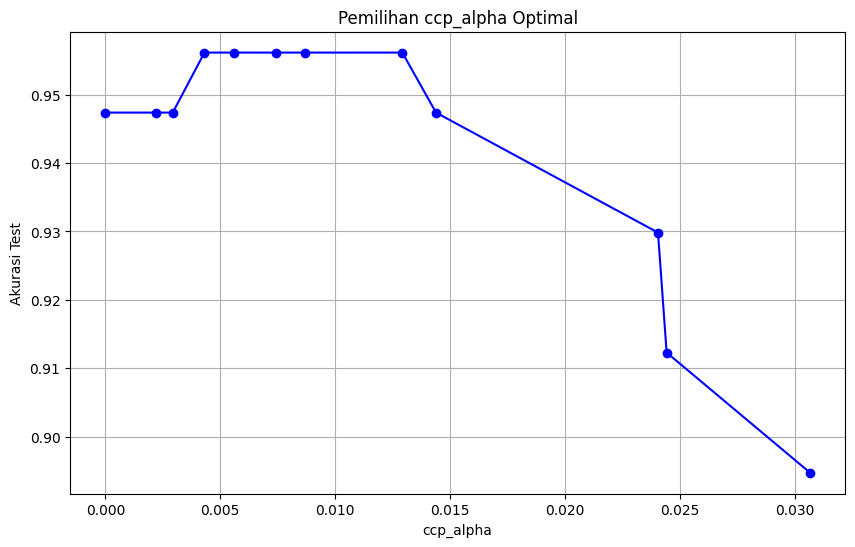


Nilai ccp_alpha optimal: 0.004311334641004935
Akurasi tertinggi: 0.9561
Jumlah leaf node pohon awal: 16
Jumlah leaf node pohon optimal: 10


In [4]:
print("=== Praktikum 2: Cost Complexity Pruning Path ===")

# Inisialisasi model pohon keputusan awal (tanpa pruning)
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

# 1. Mendapatkan jalur pruning
path = tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

# Menghapus alpha terakhir karena biasanya menghasilkan pohon kosong (hanya root)
ccp_alphas = ccp_alphas[:-1]

akurasi_test = []

# 2. Melakukan iterasi untuk setiap nilai alpha
for alpha in ccp_alphas:
    # PERBAIKAN: Menggunakan ccp_alpha (tanpa 's')
    m = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    m.fit(X_train, y_train)
    akurasi_test.append(accuracy_score(y_test, m.predict(X_test)))

# 3. Visualisasi hasil
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas, akurasi_test, marker='o', linestyle='-', color='b')
plt.xlabel("ccp_alpha")
plt.ylabel("Akurasi Test")
plt.title("Pemilihan ccp_alpha Optimal")
plt.grid(True)
plt.show()

# 4. Menentukan ccp_alpha dengan akurasi tertinggi
alpha_optimal = ccp_alphas[np.argmax(akurasi_test)]
print(f"\nNilai ccp_alpha optimal: {alpha_optimal}")
print(f"Akurasi tertinggi: {max(akurasi_test):.4f}")

# 5. Membandingkan jumlah leaf node (pohon awal vs pohon pruning optimal)
pohon_awal = DecisionTreeClassifier(random_state=42)
pohon_awal.fit(X_train, y_train)
print(f"Jumlah leaf node pohon awal: {pohon_awal.get_n_leaves()}")

# PERBAIKAN: Menggunakan ccp_alpha (tanpa 's') di sini juga
pohon_optimal = DecisionTreeClassifier(ccp_alpha=alpha_optimal, random_state=42)
pohon_optimal.fit(X_train, y_train)
print(f"Jumlah leaf node pohon optimal: {pohon_optimal.get_n_leaves()}")